# Machine Learning Project - ATP Tennis Matches 2000-2026
## Team: Petar Car, Karlo Vlašić, Jakub Cerny

In [1]:
#setup
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42

DATA_RAW = Path("../data/raw/atp_tennis.csv") # path to .csv file
DATA_DIR = Path("../data")
DATA_INTERIM = DATA_DIR / "interim" # output of Part 1, input of Part 2
FIGURE_DIR = Path("../report/figures")
DATA_INTERIM.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

def save_fig(name):
    """Save the current figure to report/figures (for the report and slides) and show it."""
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Loading data and overview

In [2]:
data = pd.read_csv(DATA_RAW, parse_dates = ["Date"]) # convert column "Date" to datetime64 type
print(data.shape)
data.head()


(68963, 17)


,Tournament,Date,Series,Court,Surface,Round,Best of,Player_1,Player_2,Winner,Rank_1,Rank_2,Pts_1,Pts_2,Odd_1,Odd_2,Score
0,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Arthurs W.,Gambill J.M.,Gambill J.M.,105,58,-1,-1,-1.0,-1.0,6-3 6-7 4-6
1,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Balcells J.,Henman T.,Henman T.,218,11,-1,-1,-1.0,-1.0,4-6 6-7
2,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Clement A.,Enqvist T.,Enqvist T.,56,5,-1,-1,-1.0,-1.0,3-6 3-6
3,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Dosedel S.,Ljubicic I.,Dosedel S.,63,77,-1,-1,-1.0,-1.0,6-4 6-2
4,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Draper S.,Norman M.,Norman M.,155,15,-1,-1,-1.0,-1.0,4-6 4-6


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 68963 entries, 0 to 68962
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Tournament  68963 non-null  str           
 1   Date        68963 non-null  datetime64[us]
 2   Series      68963 non-null  str           
 3   Court       68963 non-null  str           
 4   Surface     68963 non-null  str           
 5   Round       68963 non-null  str           
 6   Best of     68963 non-null  int64         
 7   Player_1    68963 non-null  str           
 8   Player_2    68963 non-null  str           
 9   Winner      68963 non-null  str           
 10  Rank_1      68963 non-null  int64         
 11  Rank_2      68963 non-null  int64         
 12  Pts_1       68963 non-null  int64         
 13  Pts_2       68963 non-null  int64         
 14  Odd_1       68963 non-null  float64       
 15  Odd_2       68963 non-null  float64       
 16  Score       68963 non-null  str  

## 2. Dataset selection

**Source:** "ATP Tennis 2000 - 2025 Daily update" by dissfya on Kaggle, https://www.kaggle.com/datasets/dissfya/atp-tennis-2000-2023daily-pull.

Each row is one ATP singles match with the tournament context, both players' ranking, ranking points and pre-match betting odds, the winner and the score. The task is to predict whether Player 1 wins. The table checks the requirements from section 2 of the assignment.

In [4]:
# candidate input features (before any feature engineering)
FEATURES = ["Tournament", "Date", "Series", "Court", "Surface", "Round", "Best of",
            "Rank_1", "Rank_2", "Pts_1", "Pts_2", "Odd_1", "Odd_2"]

NUMERICAL = ["Rank_1", "Rank_2", "Pts_1", "Pts_2", "Odd_1", "Odd_2"]
CATEGORICAL = ["Tournament", "Court", "Surface"]
ORDINAL = ["Series", "Round", "Best of"]

requirements = pd.DataFrame({
    "Requirement": ["Real data", "Binary classification", "8 to 30 features",
                    "N >= 1000 instances", "At least 1 numerical attribute",
                    "At least 1 categorical attribute", "At least 1 ordinal attribute"],
    "Our dataset": ["Real ATP match results", "Player 1 wins: yes / no", f"{len(FEATURES)} candidate features",
                    f"{len(data):,} matches", ", ".join(NUMERICAL), ", ".join(CATEGORICAL), ", ".join(ORDINAL)],
    "Met": ["yes" if ok else "no" for ok in [True, True, 8 <= len(FEATURES) <= 30, len(data) >= 1000,
            len(NUMERICAL) >= 1, len(CATEGORICAL) >= 1, len(ORDINAL) >= 1]],
})
requirements

,Requirement,Our dataset,Met
0,Real data,Real ATP match results,yes
1,Binary classification,Player 1 wins: yes / no,yes
2,8 to 30 features,13 candidate features,yes
3,N >= 1000 instances,"68,963 matches",yes
4,At least 1 numerical attribute,"Rank_1, Rank_2, Pts_1, Pts_2, Odd_1, Odd_2",yes
5,At least 1 categorical attribute,"Tournament, Court, Surface",yes
6,At least 1 ordinal attribute,"Series, Round, Best of",yes


## 3. Data Dictionary

In [5]:
data_dictionary = pd.DataFrame([
    ["Tournament", "Name of the tournament",                                      "Categorical (nominal)", "Feature (high cardinality)"],
    ["Date",       "Date of the match",                                           "Date",                  "Used for the split, can give date features"],
    ["Series",     "Tournament category (ATP250, ATP500, Masters 1000, Grand Slam...)", "Ordinal",         "Feature"],
    ["Court",      "Indoor or Outdoor",                                           "Categorical (binary)",  "Feature"],
    ["Surface",    "Hard, Clay, Grass or Carpet",                                 "Categorical (nominal)", "Feature"],
    ["Round",      "Round of the tournament (1st Round ... The Final)",           "Ordinal",               "Feature"],
    ["Best of",    "Maximum number of sets (3 or 5)",                             "Ordinal",               "Feature"],
    ["Player_1",   "Name of player 1",                                            "Identifier",            "Removed"],
    ["Player_2",   "Name of player 2",                                            "Identifier",            "Removed"],
    ["Winner",     "Name of the winner",                                          "Text",                  "Used to build the target, then removed"],
    ["Rank_1",     "ATP ranking of player 1 before the match (1 = best)",         "Numerical (discrete)",  "Feature"],
    ["Rank_2",     "ATP ranking of player 2 before the match (1 = best)",         "Numerical (discrete)",  "Feature"],
    ["Pts_1",      "ATP ranking points of player 1 before the match",             "Numerical (discrete)",  "Feature"],
    ["Pts_2",      "ATP ranking points of player 2 before the match",             "Numerical (discrete)",  "Feature"],
    ["Odd_1",      "Pre-match decimal betting odds for player 1",                 "Numerical (continuous)", "Feature"],
    ["Odd_2",      "Pre-match decimal betting odds for player 2",                 "Numerical (continuous)", "Feature"],
    ["Score",      "Final score of the match",                                    "Text",                  "Leakage, removed"],
], columns=["Column", "Description", "Type", "Role"])
data_dictionary

,Column,Description,Type,Role
0,Tournament,Name of the tournament,Categorical (nominal),Feature (high cardinality)
1,Date,Date of the match,Date,"Used for the split, can give date features"
2,Series,"Tournament category (ATP250, ATP500, Masters 1...",Ordinal,Feature
3,Court,Indoor or Outdoor,Categorical (binary),Feature
4,Surface,"Hard, Clay, Grass or Carpet",Categorical (nominal),Feature
5,Round,Round of the tournament (1st Round ... The Final),Ordinal,Feature
6,Best of,Maximum number of sets (3 or 5),Ordinal,Feature
7,Player_1,Name of player 1,Identifier,Removed
8,Player_2,Name of player 2,Identifier,Removed
9,Winner,Name of the winner,Text,"Used to build the target, then removed"


In [6]:
# unique values per column:
data.nunique().to_frame("unique values")

,unique values
Tournament,268
Date,6780
Series,8
Court,2
Surface,4
Round,8
Best of,2
Player_1,1563
Player_2,1541
Winner,1204


## 4. Data Quality Checks
### 4.1 Duplicates and Nan values

In [7]:
print("Duplicated rows:", data.duplicated().sum())
print("NaN values per column:")
print(data.isna().sum().to_string())

Duplicated rows: 0
NaN values per column:
Tournament    0
Date          0
Series        0
Court         0
Surface       0
Round         0
Best of       0
Player_1      0
Player_2      0
Winner        0
Rank_1        0
Rank_2        0
Pts_1         0
Pts_2         0
Odd_1         0
Odd_2         0
Score         0


### 4.2 Hidden missing values (-1)


In [8]:
SENTINEL_COLS = ["Rank_1", "Rank_2", "Pts_1", "Pts_2", "Odd_1", "Odd_2"]

missing = pd.DataFrame({
    "count of -1": (data[SENTINEL_COLS] == -1).sum(),
    "percent": ((data[SENTINEL_COLS] == -1).mean() * 100).round(2),
})
missing

,count of -1,percent
Rank_1,14,0.02
Rank_2,12,0.02
Pts_1,15652,22.70
Pts_2,15653,22.70
Odd_1,3782,5.48
Odd_2,3780,5.48


The missing values are not random. The plot below shows the share of `-1` per year.

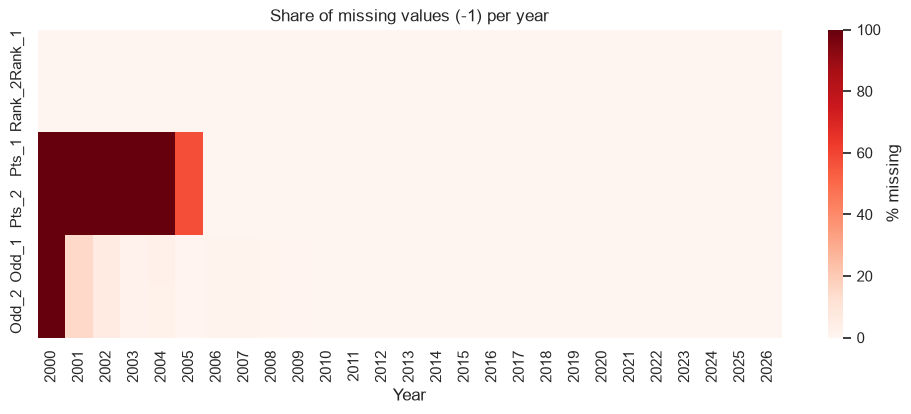

In [9]:
missing_by_year = (data[SENTINEL_COLS] == -1).groupby(data["Date"].dt.year).mean() * 100

plt.figure(figsize=(12, 4))
sns.heatmap(missing_by_year.T, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% missing"})
plt.title("Share of missing values (-1) per year")
plt.xlabel("Year")
plt.ylabel("")
save_fig("p1_missing_by_year")

In [10]:
first_pts = data.loc[data["Pts_1"] != -1, "Date"].min()
print("First match with ranking points:", first_pts.date())

First match with ranking points: 2005-07-04


Findings:
- **Ranking points (Pts)** are missing for every match before the middle of 2005. These values were simply not collected in the source for that period. About 23% of all rows are affected.
- **Odds** are missing for the whole year 2000 and only for a small number of matches after that (about 5.5% in total).
- **Ranking (Rank)** is missing in only a few matches (players without an ATP ranking).

### 4.3 Invalid values

Decimal betting odds are always greater than 1 (odds of 1.0 would mean a 100% sure win, odds of 0 are impossible).

In [11]:
odds = data[["Odd_1", "Odd_2"]]
print("Odds equal to 0:      ", ((odds == 0).sum()).to_dict())
print("Odds equal to 1.0:    ", ((odds == 1).sum()).to_dict())
print("Odds between 0 and 1: ", (((odds > 0) & (odds < 1)).sum()).to_dict())

Odds equal to 0:       {'Odd_1': 1, 'Odd_2': 1}
Odds equal to 1.0:     {'Odd_1': 52, 'Odd_2': 36}
Odds between 0 and 1:  {'Odd_1': 2, 'Odd_2': 4}


- Odds equal to **0** or **below 1** (a few values such as 0.97) are impossible, so they are treated as missing in the same way as `-1`.
- Odds equal to **1.0** appear in matches with a very strong favourite (for example Sinner or Federer against a low ranked player, with odds of 41 or more for the opponent). These look like real odds rounded to one decimal (e.g. 1.01 rounded to 1.0), so we keep them. Part 2 should keep in mind that an odd of 1.0 gives an implied probability of 100%.

### 4.4 Making missing values visible

We replace `-1` (and the impossible odds below 1) with `NaN`. This is **not** imputation. It only makes the missing values visible to pandas and scikit-learn, so they are not used as real numbers (a mean of `Pts` computed with -1 values would be wrong).
How to handle the missing values (deleting, imputing, adding an indicator) is decided in Part 2, using only the training set.

This replacement does not depend on any other row, so doing it before the train/test split does not cause data leakage.

In [12]:
data[SENTINEL_COLS] = data[SENTINEL_COLS].replace(-1, np.nan)
odds_cols = ["Odd_1", "Odd_2"]
data[odds_cols] = data[odds_cols].mask(data[odds_cols] < 1)  # odds below 1 (incl. 0) are impossible

data[SENTINEL_COLS].isna().sum().to_frame("NaN after replacement")

,NaN after replacement
Rank_1,14
Rank_2,12
Pts_1,15652
Pts_2,15653
Odd_1,3785
Odd_2,3785


### 4.5 Corrupted ranking data in two 2023 tournaments

A comment on the Kaggle dataset page reported a ranking-points anomaly in 2023. We checked it ourselves.

In normal data, the better ranked player (lower rank) almost always has more ranking points. We count the matches where this is not true:

In [13]:
inconsistent = (
    ((data["Rank_1"] < data["Rank_2"]) & (data["Pts_1"] < data["Pts_2"])) |
    ((data["Rank_1"] > data["Rank_2"]) & (data["Pts_1"] > data["Pts_2"]))
)
print("Matches where the better ranked player has fewer points:", inconsistent.sum())

data[inconsistent].groupby([data["Date"].dt.year, "Tournament"]).size().to_frame("matches")

Matches where the better ranked player has fewer points: 43


matches
Date Tournament                  
2011 Chennai Open               1
2014 Open Banco Sabadell        1
2015 Delray Beach Open          1
2021 Delray Beach Open          1
2023 Geneva Open               19
     Lyon Open                 18
2025 Chengdu Open               1
2026 Miami Open                 1

Almost all inconsistent matches come from two tournaments played in the same week: Geneva Open and Lyon Open (21 to 27 May 2023). Outside these two tournaments there are only a handful of such cases in 26 years.

The values in these two tournaments are not just slightly off. The ranking of the same player jumps for one week and then returns to normal:

In [14]:
def player_rank_history(name, start="2023-05-01", end="2023-06-15"):
    """Ranking of one player in all his matches between start and end."""
    rows = data[((data["Player_1"] == name) | (data["Player_2"] == name)) & data["Date"].between(start, end)]
    rank = np.where(rows["Player_1"] == name, rows["Rank_1"], rows["Rank_2"])
    return pd.DataFrame({"Date": rows["Date"].dt.date, "Tournament": rows["Tournament"], "Rank": rank})

player_rank_history("Shelton B.")

,Date,Tournament,Rank
60049,2023-05-12,Internazionali BNL d'Italia,35.0
60101,2023-05-21,Geneva Open,733.0
60166,2023-05-28,French Open,36.0


In [15]:
CORRUPTED = (
    data["Tournament"].isin(["Geneva Open", "Lyon Open"]) &
    data["Date"].between("2023-05-21", "2023-05-27")
)
print("Matches in the two affected tournaments:", CORRUPTED.sum())
data.loc[CORRUPTED, ["Tournament", "Player_1", "Player_2", "Rank_1", "Rank_2", "Pts_1", "Pts_2"]].head(10)

Matches in the two affected tournaments: 48


,Tournament,Player_1,Player_2,Rank_1,Rank_2,Pts_1,Pts_2
60100,Geneva Open,Eubanks C.,Paire B.,75.0,729.0,149.0,398.0
60101,Geneva Open,Shelton B.,Cecchinato M.,733.0,73.0,1095.0,35.0
60103,Lyon Open,Barrere G.,Moutet C.,55.0,846.0,61.0,823.0
60104,Lyon Open,Muller A.,Draper J.,832.0,60.0,639.0,100.0
60105,Lyon Open,Ramos-Vinolas A.,Varillas J. P.,648.0,97.0,782.0,66.0
60106,Geneva Open,Carballes Baena R.,Rincon D.,58.0,841.0,274.0,190.0
60107,Geneva Open,Giron M.,Bublik A.,74.0,730.0,48.0,915.0
60108,Geneva Open,Huesler M.A.,Wu Y.,839.0,59.0,719.0,81.0
60109,Geneva Open,Krajinovic F.,Mannarino A.,917.0,47.0,661.0,92.0
60110,Geneva Open,Lajovic D.,Jarry N.,862.0,54.0,899.0,51.0


Shelton was ranked around 35 the week before and the week after, but 733 in Geneva. Other values are also impossible, for example a player ranked 10 with only 240 points. All 48 matches of these two tournaments have unreliable `Rank` and `Pts`, including the ones that passed the consistency check above.

**Decision:** we set `Rank_1`, `Rank_2`, `Pts_1` and `Pts_2` to `NaN` for these 48 matches.

- We do not delete the rows: the match context, the odds and the result are still valid.
- We do not try to reconstruct the correct values from official ATP ranking lists. That would be manual work for 48 matches out of 68,963 and is not needed for M1.
- The missing values are then handled in Part 2 in the same way as all other missing values.
- This matters because these matches are in the **test set** (2023). Without the correction, corrupted inputs would affect the evaluation of the models in M2.
- The correction uses only the values of the affected rows, never the target and never statistics computed from other rows, so it does not cause data leakage.

In [16]:
data.loc[CORRUPTED, ["Rank_1", "Rank_2", "Pts_1", "Pts_2"]] = np.nan

print("Inconsistent matches after the correction:",
      (((data["Rank_1"] < data["Rank_2"]) & (data["Pts_1"] < data["Pts_2"])) |
       ((data["Rank_1"] > data["Rank_2"]) & (data["Pts_1"] > data["Pts_2"]))).sum())

Inconsistent matches after the correction: 6


## 5. Target variable

The dataset has no ready target column. We build it from `Winner`:

`target = 1` if Player 1 won the match, `target = 0` if Player 2 won.

First we check that the winner is always one of the two players.

In [17]:
winner_is_player = (data["Winner"] == data["Player_1"]) | (data["Winner"] == data["Player_2"])
print("Rows where the winner is not Player_1 or Player_2:", (~winner_is_player).sum())

data["target"] = (data["Winner"] == data["Player_1"]).astype(int)
data["target"].value_counts().to_frame("count").assign(percent=lambda d: (d["count"] / len(data) * 100).round(2))

Rows where the winner is not Player_1 or Player_2: 0


,count,percent
target,,
1,34482,50.0
0,34481,50.0


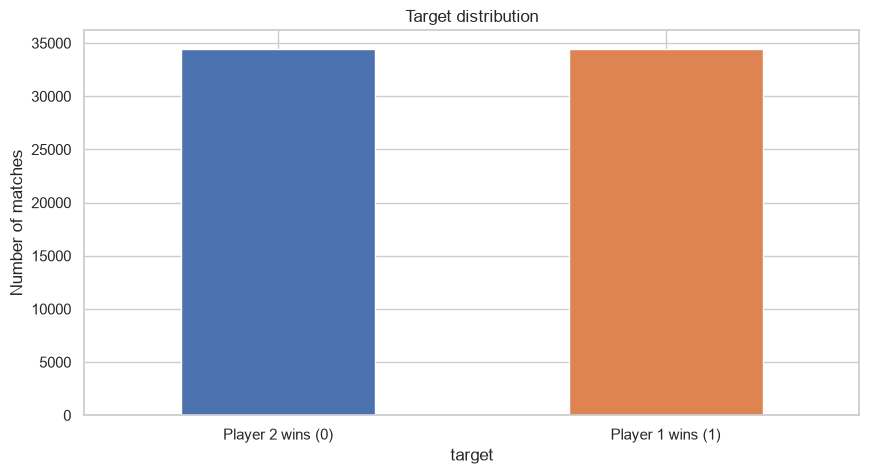

In [18]:
ax = data["target"].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["Player 2 wins (0)", "Player 1 wins (1)"], rotation=0)
ax.set_ylabel("Number of matches")
ax.set_title("Target distribution")
save_fig("p1_target_distribution")

The classes are perfectly balanced (50% / 50%). This means that accuracy is a meaningful metric in M2 and that we do not need resampling methods.

**Is the position of the player random?** If the dataset always put the better player (or the winner) as Player 1, a model could learn the position and not the tennis. We check how often Player 1 is the better ranked player:

In [19]:
both_ranked = data.dropna(subset=["Rank_1", "Rank_2"])
print(f"Player 1 is better ranked in {(both_ranked['Rank_1'] < both_ranked['Rank_2']).mean():.1%} of matches")
print(f"Player 1 name is alphabetically first in {(data['Player_1'] < data['Player_2']).mean():.1%} of matches")

Player 1 is better ranked in 49.9% of matches
Player 1 name is alphabetically first in 49.7% of matches


Both values are close to 50%, so the assignment of players to position 1 and 2 is not related to ranking, name or result. The target is not trivial.

## 6. Columns removed (data leakage and identifiers)

- **Score**: known only after the match. With the score the winner can be read directly, so this is pure data leakage.
- **Winner**: the target was built from it, so it must be removed from the inputs.
- **Player_1, Player_2**: player names are identifiers with 1,500+ unique values. A model would memorise names instead of learning general patterns, and new players that appear in the test period would be unknown. The information about player strength is already in the ranking, points and odds.

`Odd_1` and `Odd_2` are **not** leakage, because betting odds are published before the match starts. They are, however, the strongest single predictor (see section 8.4), so in M2 it will be interesting to compare models with and without odds.

In [20]:
data = data.drop(columns=["Score", "Winner", "Player_1", "Player_2"])
print(data.shape)
data.head()

(68963, 14)


,Tournament,Date,Series,Court,Surface,Round,Best of,Rank_1,Rank_2,Pts_1,Pts_2,Odd_1,Odd_2,target
0,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,105.0,58.0,NaN,NaN,NaN,NaN,0
1,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,218.0,11.0,NaN,NaN,NaN,NaN,0
2,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,56.0,5.0,NaN,NaN,NaN,NaN,0
3,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,63.0,77.0,NaN,NaN,NaN,NaN,1
4,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,155.0,15.0,NaN,NaN,NaN,NaN,0


## 7. Train/test split

We use a **temporal split** instead of a random one:

- **Training set:** all matches from 2000-01-01 to 2021-12-31
- **Test set:** all matches from 2022-01-01 onward

Why temporal:
- in practice a model is trained on past matches and used on future matches, and the temporal split simulates exactly that
- with a random split, the model would be trained on matches from 2025 and tested on matches from 2010, which gives an optimistic and unrealistic result
- tennis changes over time (new players, Carpet surface disappears, tournament categories were renamed in 2009), and a temporal split shows if the preparation of the data handles these changes

The split is done **before** any statistics are computed for cleaning (imputation values, scaling, encoding). All of these are learned from the training set only and then applied to the test set, so no information from the test set leaks into the training.

A random split is not used, so `random_state` is not needed here. It stays defined in the setup for later steps that use randomness.

In [21]:
TEST_START = pd.Timestamp("2022-01-01")

data = data.sort_values("Date", kind="stable").reset_index(drop=True)
train = data[data["Date"] < TEST_START].copy()
test = data[data["Date"] >= TEST_START].copy()

split_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "share": [len(train) / len(data), len(test) / len(data)],
    "from": [train["Date"].min().date(), test["Date"].min().date()],
    "to": [train["Date"].max().date(), test["Date"].max().date()],
    "target = 1": [train["target"].mean(), test["target"].mean()],
}, index=["train", "test"]).round(3)
split_summary

,rows,share,from,to,target = 1
train,56410,0.818,2000-01-03,2021-11-21,0.5
test,12553,0.182,2022-01-03,2026-10-18,0.5


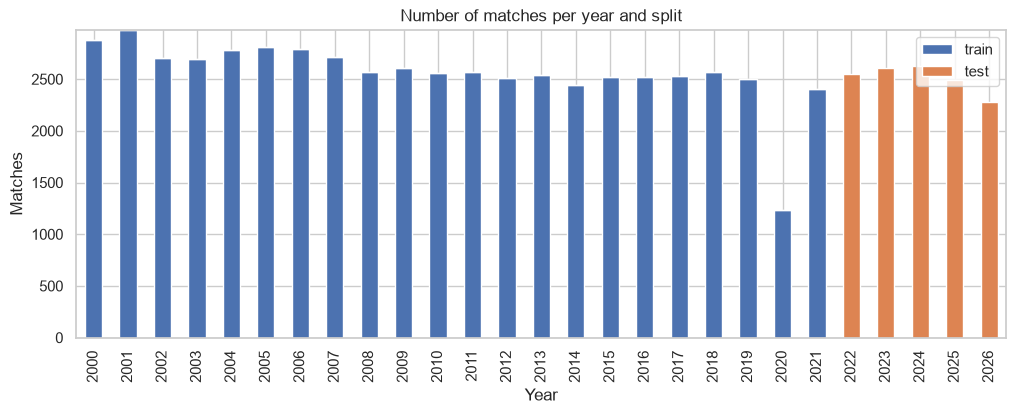

In [22]:
per_year = data.groupby([data["Date"].dt.year, np.where(data["Date"] < TEST_START, "train", "test")]).size().unstack(fill_value=0)
per_year[["train", "test"]].plot(kind="bar", stacked=True, figsize=(12, 4), color=["#4C72B0", "#DD8452"])
plt.title("Number of matches per year and split")
plt.xlabel("Year")
plt.ylabel("Matches")
save_fig("p1_split_per_year")

The test set has about 18% of the matches, close to the usual 80/20 ratio. The class balance is the same in both sets. 2020 has about half the usual number of matches because of the COVID-19 break in the season.

Some categories exist only in one of the two sets. This is important for Part 2:

In [23]:
for col in ["Series", "Surface", "Round"]:
    ct = pd.crosstab(data[col], np.where(data["Date"] < TEST_START, "train", "test"))[["train", "test"]]
    print(ct, "\n")

col_0               train  test
Series                         
ATP250              13659  4707
ATP500               4824  2071
Grand Slam          10562  2434
International       11752     0
International Gold   3620     0
Masters              5029     0
Masters 1000         6636  3282
Masters Cup           328    59 

col_0    train  test
Surface             
Carpet    1632     0
Clay     18239  3913
Grass     6217  1516
Hard     30322  7124 

col_0          train  test
Round                     
1st Round      25984  5560
2nd Round      15636  3629
3rd Round       3974   924
4th Round        959   350
Quarterfinals   5360  1147
Round Robin      379    47
Semifinals      2733   592
The Final       1385   304 



In [24]:
# first and last appearance of every Series name
data.groupby("Series")["Date"].agg(["min", "max"]).sort_values("min")

,min,max
Series,,
International,2000-01-03,2008-10-26
Grand Slam,2000-01-17,2026-09-13
International Gold,2000-02-14,2008-10-12
Masters,2000-03-13,2008-11-02
Masters Cup,2000-11-27,2025-11-16
ATP250,2009-01-04,2026-09-29
ATP500,2009-02-09,2026-10-06
Masters 1000,2009-03-12,2026-10-18


- `International`, `International Gold` and `Masters` appear only in the training set. In 2009 the ATP renamed its tournament categories and the dataset follows the new names from that year (the old names end in 2008 and the new ones start in 2009). They are the same tournament levels under new names: International = ATP250, International Gold = ATP500, Masters = Masters 1000. If they are not merged, the encoder will see them as different categories.
- `Carpet` appears only in the training set (last used in 2009).

Saving the split for Part 2:

In [25]:
train.to_csv(DATA_INTERIM / "train.csv", index=False)
test.to_csv(DATA_INTERIM / "test.csv", index=False)
print("Saved:", DATA_INTERIM / "train.csv", train.shape, "|", DATA_INTERIM / "test.csv", test.shape)

Saved: ../data/interim/train.csv (56410, 14) | ../data/interim/test.csv (12553, 14)


## 8. Exploratory data analysis (training set only)

From here on all analysis is done on the **training set**. The test set is kept aside so that decisions are not influenced by it.

Some extra columns are created on a copy (`eda`) only for the plots. They are not saved; feature engineering is part of Part 2.

In [26]:
eda = train.copy()
eda["year"] = eda["Date"].dt.year
eda["log_rank_ratio"] = np.log(eda["Rank_2"] / eda["Rank_1"])  # > 0 means Player 1 is better ranked

# matches where both players have a ranking and the rankings are different
ranked = eda.dropna(subset=["Rank_1", "Rank_2"])
ranked = ranked[ranked["Rank_1"] != ranked["Rank_2"]].copy()
ranked["p1_better_ranked"] = (ranked["Rank_1"] < ranked["Rank_2"]).astype(int)
ranked["favourite_won"] = (ranked["p1_better_ranked"] == ranked["target"]).astype(int)

### 8.1 Numerical attributes

In [27]:
eda[NUMERICAL].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Rank_1,56396.0,75.74,99.03,1.0,25.0,53.00,92.00,2159.0
Rank_2,56398.0,75.30,96.82,1.0,24.0,53.00,92.00,2146.0
Pts_1,40758.0,1462.80,1865.18,1.0,574.0,876.00,1495.00,16950.0
Pts_2,40757.0,1473.65,1897.14,1.0,575.0,880.00,1500.00,16950.0
Odd_1,52635.0,2.63,2.64,1.0,1.4,1.83,2.75,67.0
Odd_2,52635.0,2.62,2.58,1.0,1.4,1.83,2.75,51.0


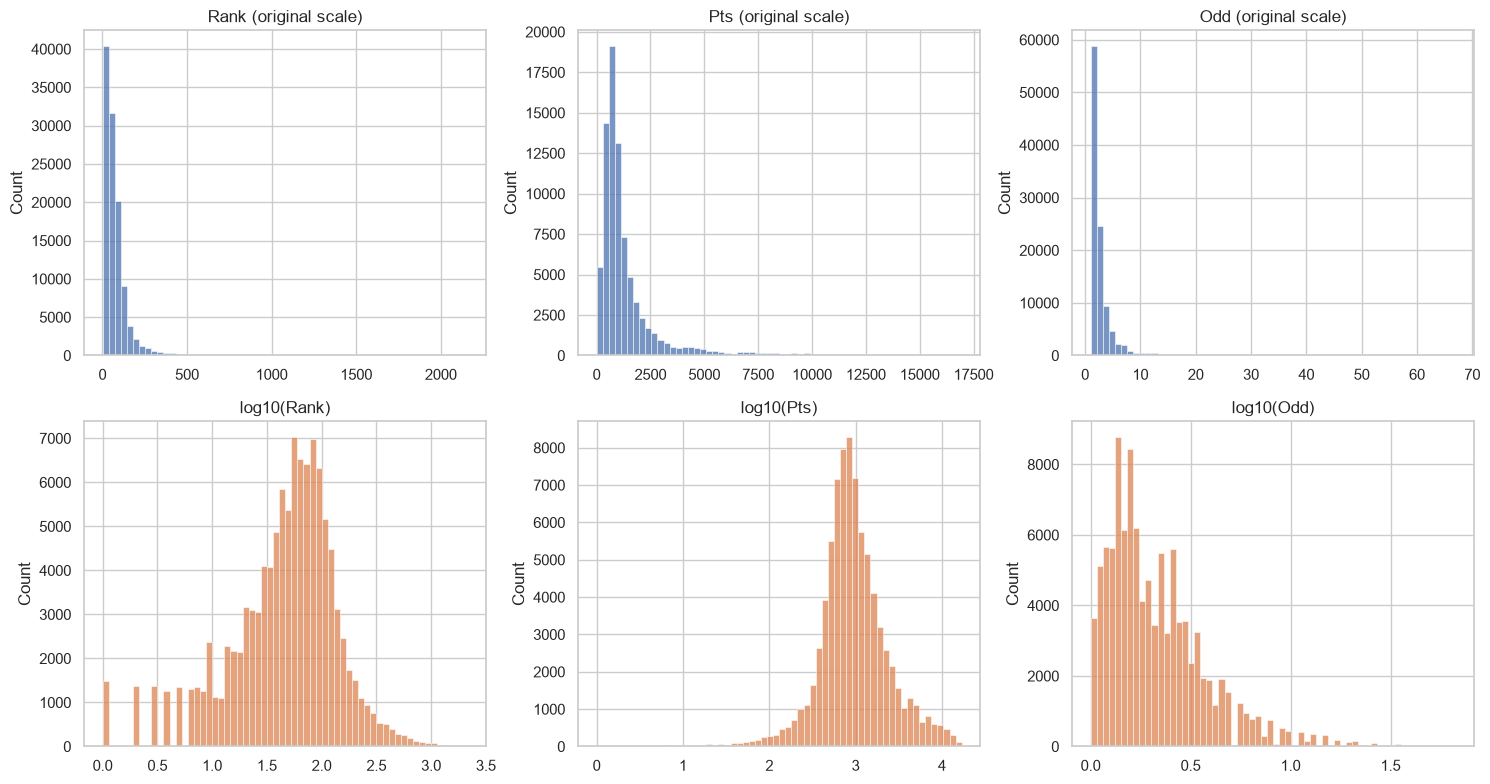

In [28]:
# both players together, because Rank_1 and Rank_2 describe the same quantity
pairs = {"Rank": ["Rank_1", "Rank_2"], "Pts": ["Pts_1", "Pts_2"], "Odd": ["Odd_1", "Odd_2"]}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (name, cols) in enumerate(pairs.items()):
    values = pd.concat([eda[cols[0]], eda[cols[1]]]).dropna()
    sns.histplot(values, bins=60, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{name} (original scale)")
    sns.histplot(np.log10(values), bins=60, ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"log10({name})")
plt.tight_layout()
save_fig("p1_numerical_distributions")

All three quantities are strongly right-skewed: most players are ranked in the top 100, but a few have rankings in the thousands; most odds are between 1.1 and 4, but outsiders can have odds above 20 (in `describe()` the mean is much larger than the median).
On a log scale the distributions are much closer to symmetric. This suggests a log transformation in Part 2, which is useful for models sensitive to scale and outliers (for example logistic regression, KNN, SVM).

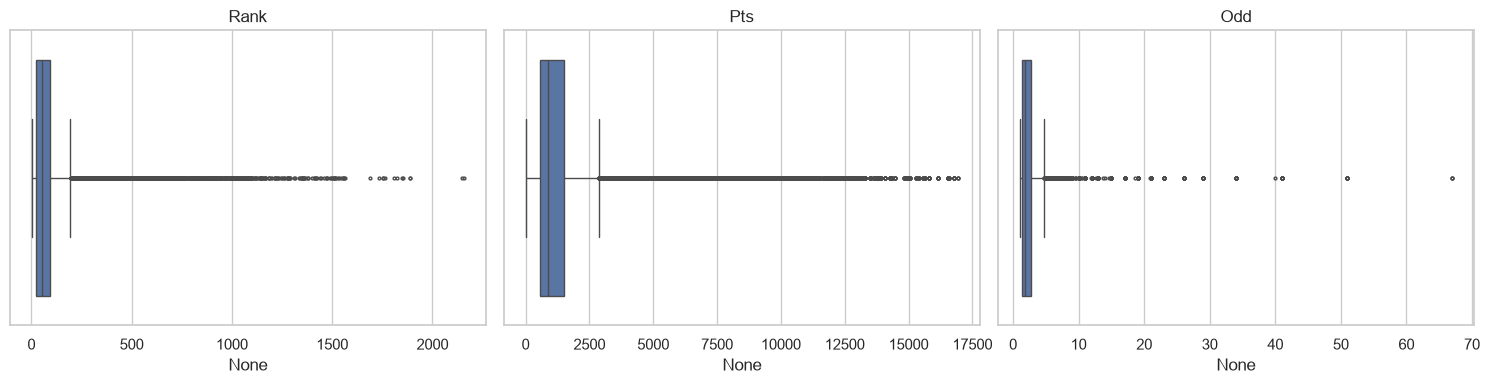

Rank: 5.9% of values above the IQR upper fence (194.0), max = 2159.0
Pts: 10.3% of values above the IQR upper fence (2875.0), max = 16950.0
Odd: 9.0% of values above the IQR upper fence (4.8), max = 67.0


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (name, cols) in enumerate(pairs.items()):
    values = pd.concat([eda[cols[0]], eda[cols[1]]]).dropna()
    sns.boxplot(x=values, ax=axes[i], color="#4C72B0", fliersize=2)
    axes[i].set_title(name)
plt.tight_layout()
save_fig("p1_numerical_boxplots")

for name, cols in pairs.items():
    values = pd.concat([eda[cols[0]], eda[cols[1]]]).dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    print(f"{name}: {(values > upper).mean():.1%} of values above the IQR upper fence ({upper:.1f}), max = {values.max()}")

The boxplots show many points outside the IQR fences. These are **not errors**: a player ranked 1,500 or odds of 30 are real values (qualifiers, wild cards, players coming back from injury). Removing them would remove real and informative matches (big upsets). Instead of deleting them, Part 2 should reduce their influence with a log transformation.

### 8.2 Categorical and ordinal attributes

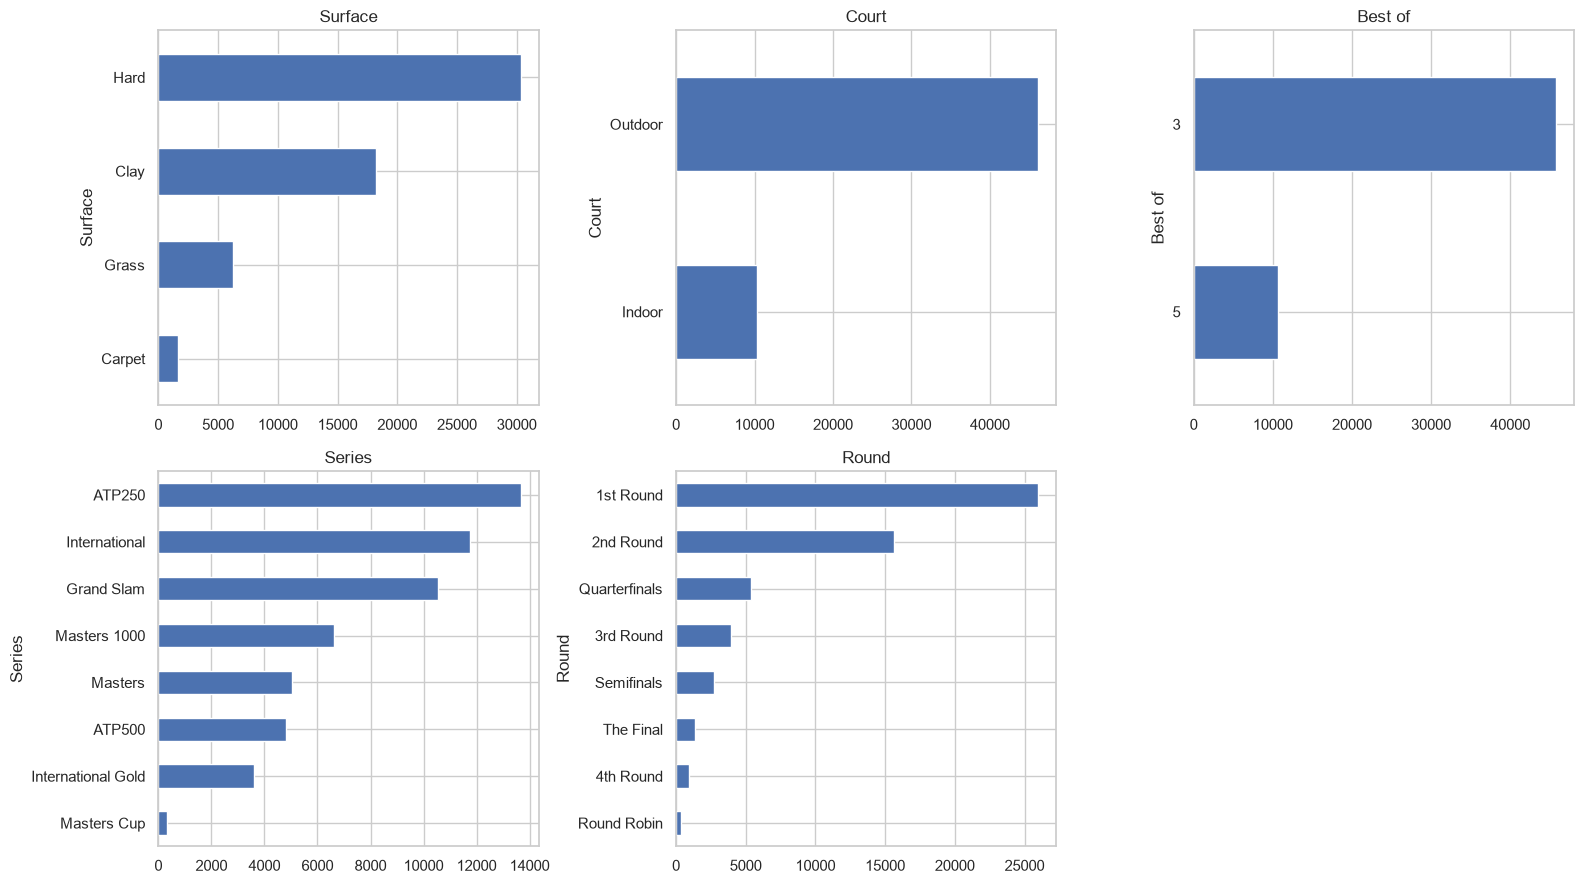

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["Surface", "Court", "Best of", "Series", "Round"]):
    eda[col].value_counts().plot(kind="barh", ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.invert_yaxis()
axes.flat[-1].axis("off")
plt.tight_layout()
save_fig("p1_categorical_counts")

In [31]:
print("Unique tournaments in train:", eda["Tournament"].nunique())
print("Tournaments with fewer than 50 matches:", (eda["Tournament"].value_counts() < 50).sum())

Unique tournaments in train: 244
Tournaments with fewer than 50 matches: 58


- **Surface:** Hard is the most common surface, followed by Clay and Grass. Carpet is rare.
- **Court:** most matches are outdoor.
- **Best of:** 5 sets are played only at Grand Slams (and in some older finals); everything else is best of 3.
- **Series:** shows the renaming problem from section 7. After merging there are 5 levels with a natural order: ATP250 < ATP500 < Masters 1000 < Masters Cup (ATP Finals) < Grand Slam.
- **Round:** has a natural order from 1st Round to The Final. `Round Robin` is the group stage of the ATP Finals (Masters Cup) and does not fit into this order, so Part 2 has to decide how to encode it.
- **Tournament:** has many categories (high cardinality) and many tournaments with few matches. One-hot encoding would create hundreds of columns, so Part 2 should consider removing it or grouping it.

### 8.3 Changes over time

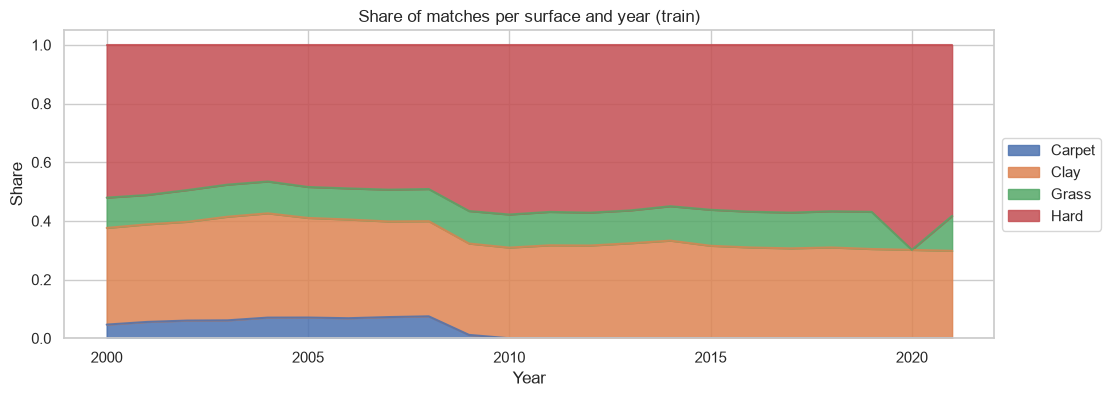

In [32]:
surface_share = pd.crosstab(eda["year"], eda["Surface"], normalize="index")
surface_share.plot(kind="area", stacked=True, figsize=(12, 4), alpha=0.85)
plt.title("Share of matches per surface and year (train)")
plt.ylabel("Share")
plt.xlabel("Year")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
save_fig("p1_surface_over_time")

Carpet disappears from the calendar after 2009, which explains why it appears only in the training set. Together with the renaming of the Series categories (section 7), this shows that the data changes over time and that the encoding in Part 2 and 3 has to handle categories that exist only in one period.

### 8.4 Attributes and the target

Because Player 1 and Player 2 are assigned randomly, **match context attributes alone** (surface, round, series) can not predict who wins. On any surface, Player 1 wins about 50% of the time:

In [33]:
eda.groupby("Surface")["target"].agg(["mean", "count"]).round(3)

,mean,count
Surface,,
Carpet,0.498,1632
Clay,0.500,18239
Grass,0.500,6217
Hard,0.500,30322


What matters is the **difference between the two players**. The plot shows the win rate of Player 1 depending on how much better (or worse) his ranking is than the opponent's.

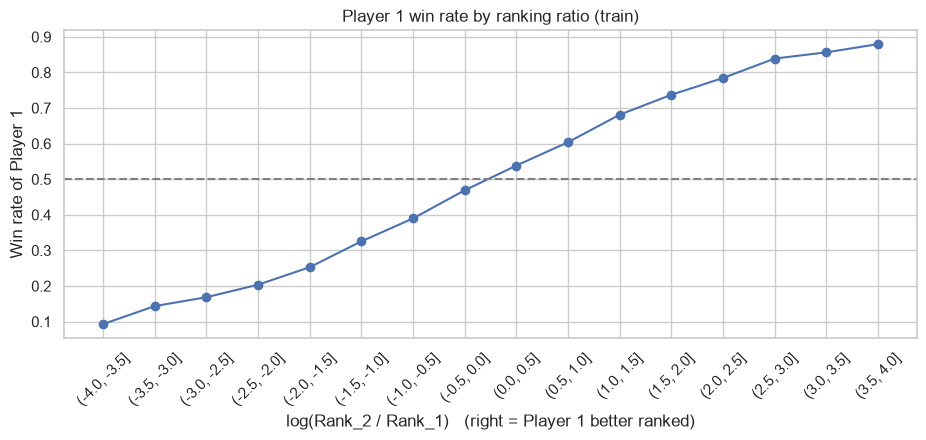

In [34]:
eda["rank_ratio_bin"] = pd.cut(eda["log_rank_ratio"], bins=np.arange(-4, 4.5, 0.5))
win_by_bin = eda.groupby("rank_ratio_bin", observed=True)["target"].agg(["mean", "count"])
win_by_bin = win_by_bin[win_by_bin["count"] >= 100]

plt.figure(figsize=(11, 4))
plt.plot(range(len(win_by_bin)), win_by_bin["mean"], marker="o")
plt.xticks(range(len(win_by_bin)), [str(b) for b in win_by_bin.index], rotation=45)
plt.axhline(0.5, color="grey", linestyle="--")
plt.xlabel("log(Rank_2 / Rank_1)   (right = Player 1 better ranked)")
plt.ylabel("Win rate of Player 1")
plt.title("Player 1 win rate by ranking ratio (train)")
save_fig("p1_winrate_by_rank_ratio")

In [35]:
fav = eda.dropna(subset=["Odd_1", "Odd_2"])
fav = fav[fav["Odd_1"] != fav["Odd_2"]]
favourite_wins = ((fav["Odd_1"] < fav["Odd_2"]).astype(int) == fav["target"]).mean()

print(f"Better ranked player wins:  {ranked['favourite_won'].mean():.1%}")
print(f"Betting favourite wins:     {favourite_wins:.1%}")

Better ranked player wins:  65.5%
Betting favourite wins:     70.4%


The relationship is clear and monotonic: the larger the ranking advantage, the more often Player 1 wins. The better ranked player wins about two thirds of the matches, and the betting favourite wins even more often. These two simple rules are useful **baselines** for M2: a model that is not better than "pick the betting favourite" is not useful.

Does the better ranked player win more often in some contexts?

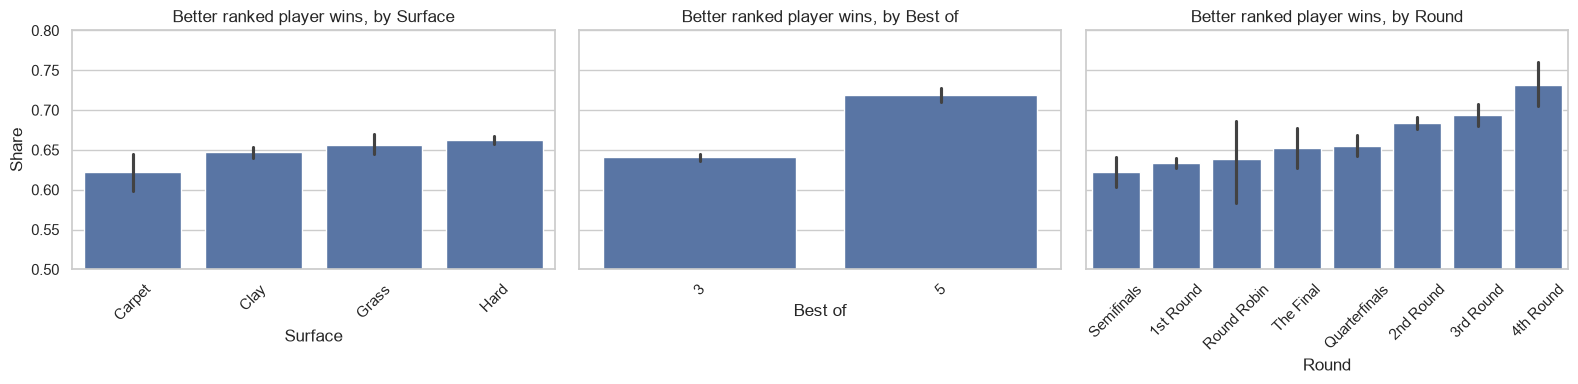

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["Surface", "Best of", "Round"]):
    order = ranked.groupby(col)["favourite_won"].mean().sort_values().index
    sns.barplot(data=ranked, x=col, y="favourite_won", order=order, ax=ax, color="#4C72B0", errorbar=("ci", 95))
    ax.set_ylim(0.5, 0.8)
    ax.set_title(f"Better ranked player wins, by {col}")
    ax.set_ylabel("Share")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save_fig("p1_favourite_by_context")

The better ranked player wins clearly more often in best of 5 matches (72% vs 64%), because more sets leave less room for luck. On Hard courts the favourite wins a bit more often than on Clay and Carpet. By round, the favourite wins least often in the semifinals and the 1st round, and most often in the 2nd to 4th rounds of big tournaments, where top players meet much weaker opponents. In late rounds the two players are usually closer in level.

So the context attributes are not useless: they **change the effect** of the ranking difference. Models that can learn interactions (trees, ensembles) may benefit from them in M2.

### 8.5 Correlation between numerical attributes

Spearman correlation is used because the distributions are skewed and the relationships are monotonic but not linear.

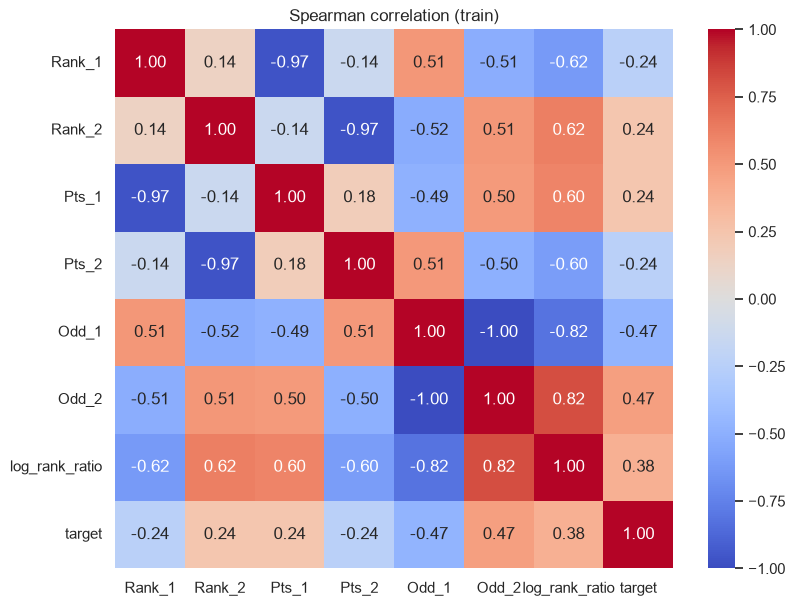

In [37]:
corr_cols = NUMERICAL + ["log_rank_ratio", "target"]
corr = eda[corr_cols].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation (train)")
save_fig("p1_correlation_heatmap")

- **Rank and Pts of the same player are almost perfectly correlated** (about -0.97, negative because rank 1 has the most points). As explained in the lectures, highly correlated features are redundant. Part 2 should keep only one of them or combine them, which also solves a big part of the missing value problem (Pts is missing before 2005, Rank almost never).
- **Rank and Odds** of the same player are moderately correlated (about 0.5): bookmakers use the ranking when they set the odds, but also other information (form, surface, injuries).
- **Odd_1 and Odd_2** have a correlation of -1.00 in ranks: when one player is the favourite, the other is the outsider. Keeping both raw columns adds little; one feature built from both (e.g. implied probability) is enough.
- The features of a single player have a weak correlation with the target. The **ranking ratio** and the **odds** have a much stronger one, which confirms that features describing the difference between the players should be built in Part 2.

### 8.6 Statistical test

A t-test (Welch version, which does not assume equal variances) checks if the mean of `log_rank_ratio` is different between matches won by Player 1 and matches won by Player 2.

In [38]:
won = eda.loc[eda["target"] == 1, "log_rank_ratio"].dropna()
lost = eda.loc[eda["target"] == 0, "log_rank_ratio"].dropna()
t_stat, p_value = stats.ttest_ind(won, lost, equal_var=False)
print(f"mean when Player 1 wins:  {won.mean():.3f}")
print(f"mean when Player 1 loses: {lost.mean():.3f}")
print(f"t = {t_stat:.2f}, p-value = {p_value:.3g}")

mean when Player 1 wins:  0.571
mean when Player 1 loses: -0.571
t = 96.72, p-value = 0


The p-value is practically zero, so we reject the null hypothesis that the two means are equal. The ranking difference is significantly different between the two classes, which confirms that it is a relevant feature.

### 8.7 Pair plot

A pair plot on a random sample of 3,000 training matches (a sample is used because 56,000 points would make the plot unreadable and slow).

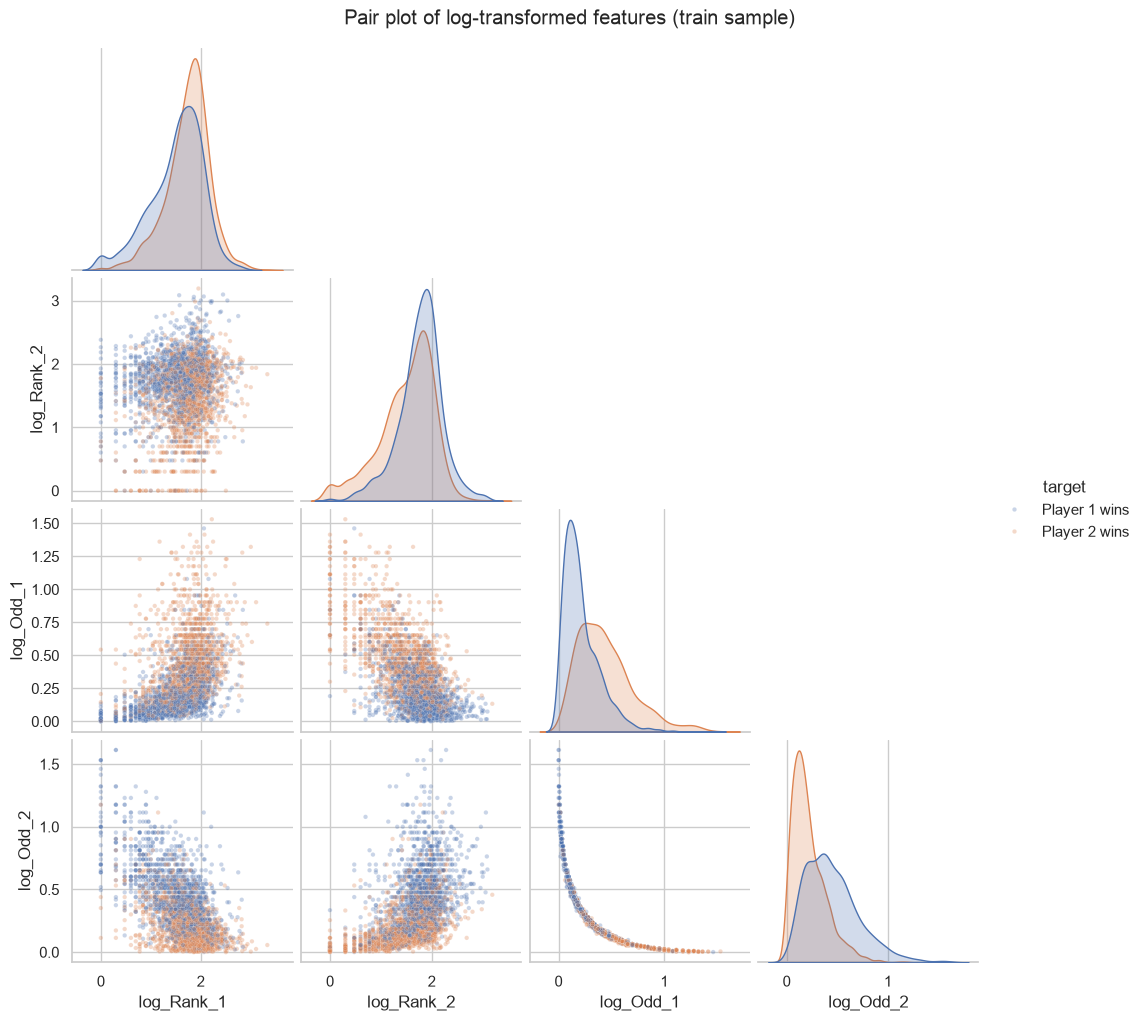

In [39]:
sample = eda.dropna(subset=["Rank_1", "Rank_2", "Odd_1", "Odd_2"]).sample(3000, random_state=RANDOM_STATE)
pair_df = pd.DataFrame({
    "log_Rank_1": np.log10(sample["Rank_1"]),
    "log_Rank_2": np.log10(sample["Rank_2"]),
    "log_Odd_1": np.log10(sample["Odd_1"]),
    "log_Odd_2": np.log10(sample["Odd_2"]),
    "target": sample["target"].map({0: "Player 2 wins", 1: "Player 1 wins"}),
})
g = sns.pairplot(pair_df, hue="target", plot_kws={"alpha": 0.3, "s": 10}, corner=True)
g.figure.suptitle("Pair plot of log-transformed features (train sample)", y=1.02)
save_fig("p1_pairplot")

In the `log_Odd_1` vs `log_Odd_2` panel the classes are well separated along the diagonal (whoever has the lower odds usually wins). For the rankings the classes overlap more, which shows that rankings alone are a weaker predictor than odds.

## 9. Summary of Part 1 and open issues for Part 2

Done: `-1` and impossible odds replaced with `NaN`, corrupted Rank/Pts in Geneva and Lyon 2023 set to `NaN`, target created, `Score`, `Winner` and player names removed, temporal split (train 2000-2021, test 2022-2026).

| # | Open issue for Part 2 (fit on train only) | Section |
|---|---|---|
| 1 | Merge old and new `Series` names | 7 |
| 2 | Encode `Round Robin` inside the ordinal `Round` | 8.2 |
| 3 | Missing `Pts` (about 23%, before mid-2005) | 4.2, 8.5 |
| 4 | Missing `Odd` (about 5.5%) and a few `Rank` | 4.2, 4.5 |
| 5 | Skew and outliers in Rank, Pts, Odds: log transform | 8.1 |
| 6 | Rank and Pts are redundant | 8.5 |
| 7 | Build difference features between the players | 8.4, 8.5 |
| 8 | Rare `Carpet`, high cardinality `Tournament` | 7, 8.2 |
| 9 | `Date`: drop or extract features | 7 |